# AGN UV reverberation: an inverse story
## Problem
Recover latent continuum and emission-line histories and top-hat delays from three noisy IUE curves. This task has **no independently observed dense GT**. The original-method result is a numerical reference, not truth. Different transfer functions can explain similar observations. We actively reconstruct all180measurements below.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np,matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src import visualization as vis
obs=load_data(ROOT/'data/raw_data.npz')
with np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as z: original={k:z[k] for k in z.files}
print('Real observed epochs per channel:',obs.shape[1],'; total flux measurements:',obs.shape[0]*obs.shape[1])

Real observed epochs per channel: 60 ; total flux measurements: 180


## Data
These are complete60-epoch continuum1337 Angstrom, Lyman alpha and C IV time-averaged1989IUE measurements of NGC5548. The original providers average exposures within an observing shift, rather than providing raw satellite detector arrays here. Continuum units are1e-15 erg s^-1 cm^-2 Angstrom^-1; line units1e-13 erg s^-1 cm^-2. Time is observer-frame JD-2440000. Error bars are supplied1-sigma values; unavailable cross-channel calibration covariance is not invented.

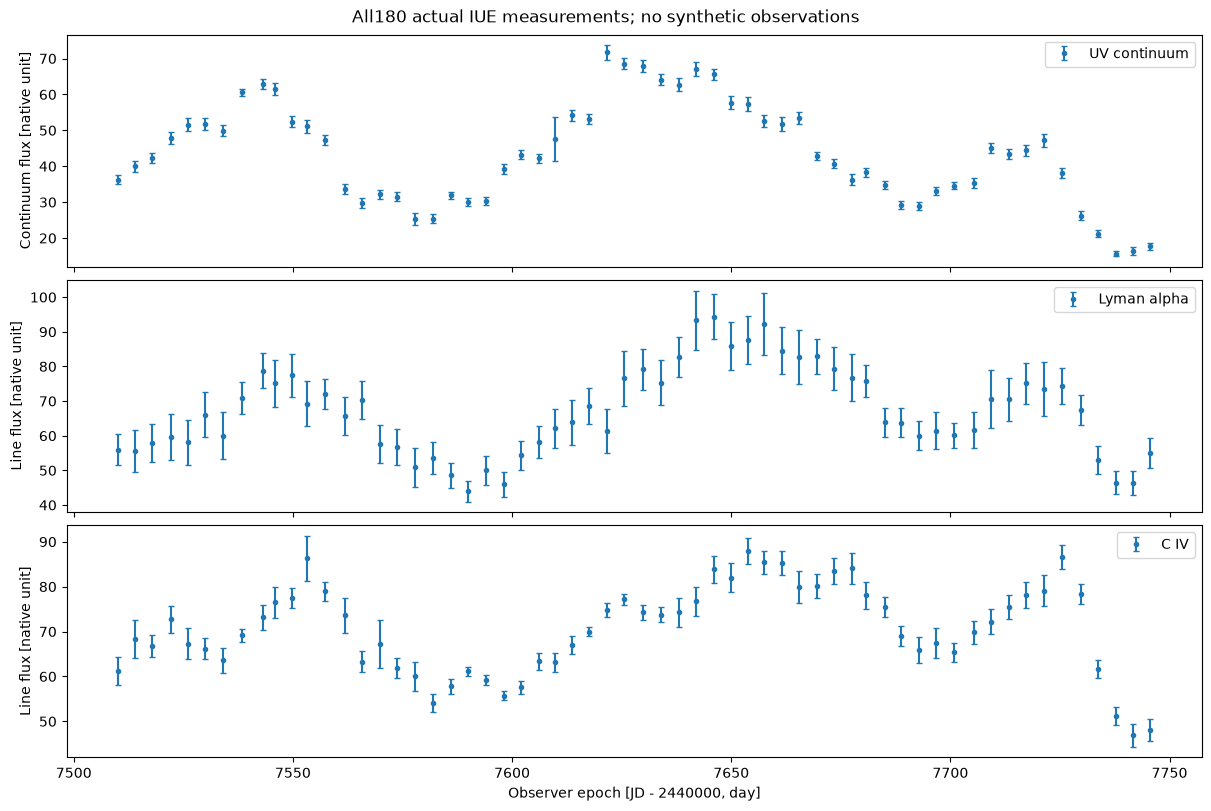

In [2]:
vis.observations(obs); plt.show()

## Physics
The zero-mean continuum c(t) is a stationary random process. Its covariance is
$$K(t,t')=\sigma^2\exp(-|t-t'|/\tau).$$
Here sigma is variability amplitude and tau damping time. The line response with centroid d, width w and scale a is
$$s(t)=\frac{a}{w}\int_{d-w/2}^{d+w/2}c(t-u)\,du.$$
Measured flux is channel mean mu plus latent signal s plus noise epsilon. This is a noisy convolution inverse. All lag/width/time values use days; response scale converts native flux units. Integrating the continuum covariance against the two response functions produces the explicit cross-channel covariance. Independent numerical integration tests check those antiderivatives. A delay probes a response scale, not a unique3Dshape or black-hole mass.

## Method
Let y be sample-centered data, L the channel-indicator matrix, C the convolved covariance plus diagonal noise, and P the matrix defined below. Marginalize unknown constant means:
$$P=L^TC^{-1}L,\quad q=P^{-1}L^TC^{-1}y,$$
$$\log\mathcal L=-\tfrac12y^T[C^{-1}-C^{-1}LP^{-1}L^TC^{-1}]y-\tfrac12\log|C|-\tfrac12\log|P|.$$
The mean correction is q. Upper-Cholesky solves evaluate this objective. We run all3predeclared Nelder-Mead starts; any iteration/evaluation limit causes a native-equivalent simplex restart, with a fixed maximum of5. The original first2starts needed one restart; their warnings remain in provenance. We select the greatest objective and condition the process to produce600points per channel. This is the original code's MAP route, **not its full MCMC posterior**. We preserve and compare all local modes instead of treating a single optimizer return as unique truth.

In [3]:
started=time.perf_counter()
fresh,info=reconstruct(obs)
seconds=time.perf_counter()-started
print('Actual complete reconstruction seconds:',seconds)
print('All converged mode objectives:',info['all_logp'])
print('Selected parameters [log sigma,log tau,lag,width,scale,...]:',info['parameters'])
for row in info['rounds']: print(row)
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',**fresh)
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert report['passed']
np.savez_compressed(ROOT/'notebooks/reference_outputs/cleaned_measurements.npz',**fresh,time=info['time'],conditional_sd=info['conditional_sd'],all_parameters=info['all_parameters'],all_logp=info['all_logp'])
(ROOT/'notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(dict(seconds=seconds,rounds=info['rounds'],report=report),indent=2),encoding='utf8')

Actual complete reconstruction seconds: 13.651093399967067
All converged mode objectives: [-431.72080871 -435.00276286 -438.03646622]
Selected parameters [log sigma,log tau,lag,width,scale,...]: [ 2.69655328  1.19475003  9.67027092 17.01667082  1.09477467 12.12265108
  6.74370938  0.805841  ]
{'start': 0, 'attempt': 0, 'objective': 433.7125156419178, 'iterations': 1106, 'evaluations': 1600, 'warning': 1}
{'start': 0, 'attempt': 1, 'objective': 431.7208087147605, 'iterations': 412, 'evaluations': 630, 'warning': 0}
{'start': 1, 'attempt': 0, 'objective': 435.0760887680619, 'iterations': 1131, 'evaluations': 1600, 'warning': 1}
{'start': 1, 'attempt': 1, 'objective': 435.0027628607006, 'iterations': 480, 'evaluations': 726, 'warning': 0}
{'start': 2, 'attempt': 0, 'objective': 438.0364662220597, 'iterations': 821, 'evaluations': 1231, 'warning': 0}
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "transfer_scaled_error": 0.0,
    "continuum_log_error": 0.0,
    "profile_rmse_0"

2109

## Results
Full curves, original numerical reference, fresh prediction and conditional1SDare compared below. Grey areas are extrapolation. Residual WRMS is measured against observed flux and supplied errors, not against latent truth. Conditional SD fixes all fit parameters and means, so it is narrower than full uncertainty.

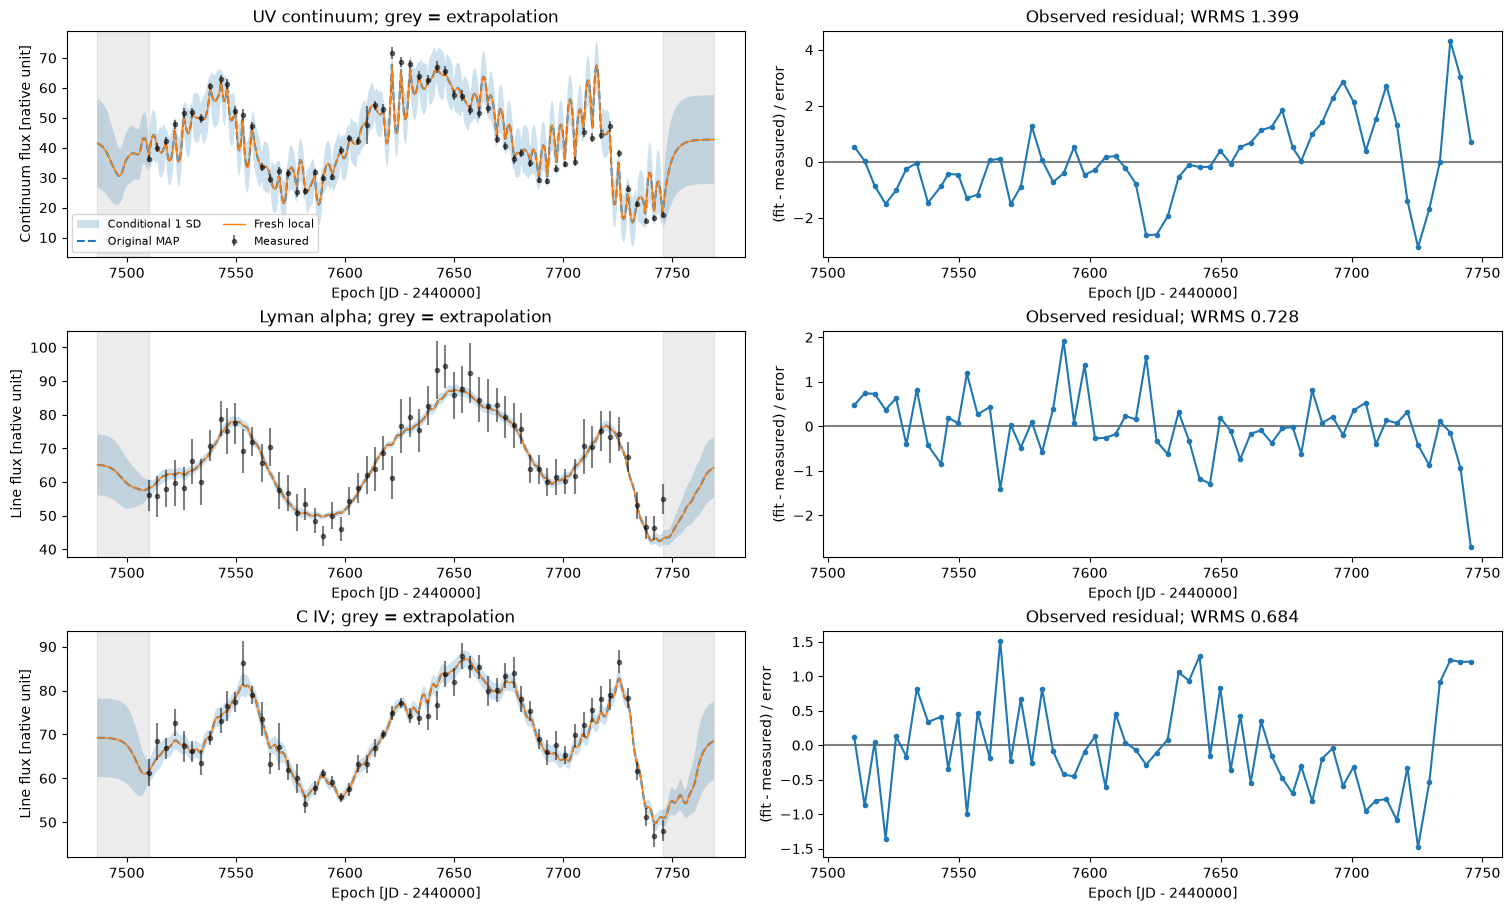

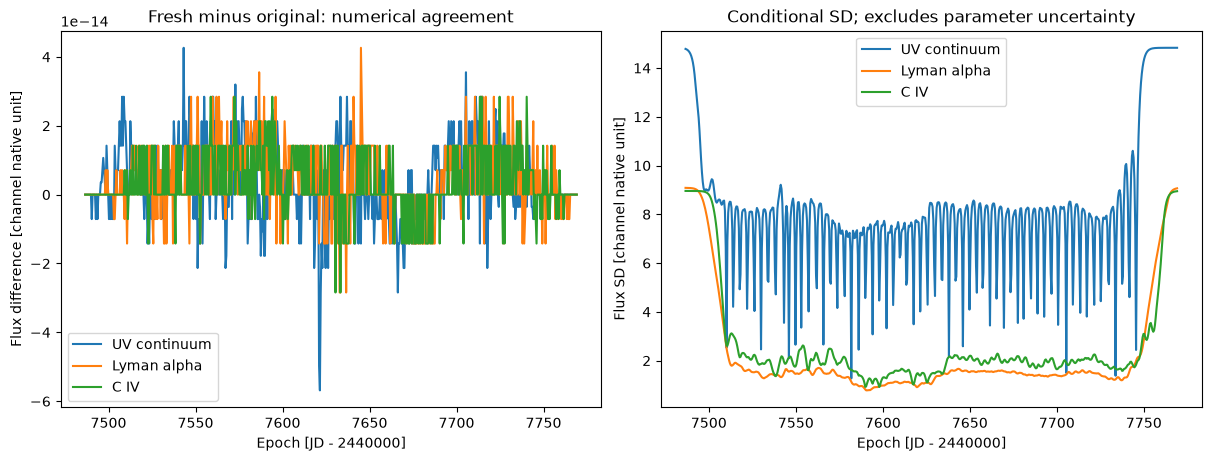

In [4]:
vis.reconstruction(obs,fresh,info,original); plt.show()
vis.parity_uncertainty(fresh,info,original); plt.show()

### Transfer modes and identifiability
The following transfer functions and histories are all actually recomputed from the three converged fits. The lowest-objective mode reaches the minimum allowed C IV width; this is a boundary solution, not evidence for an infinitely thin gas shell. Objective gaps are not posterior probabilities.

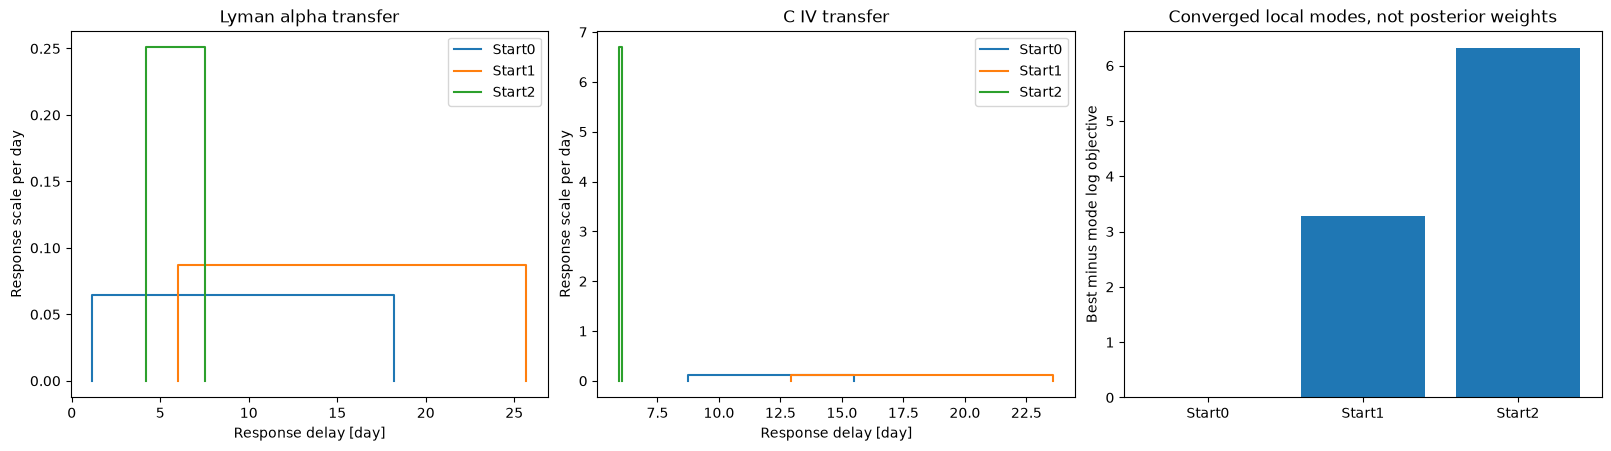

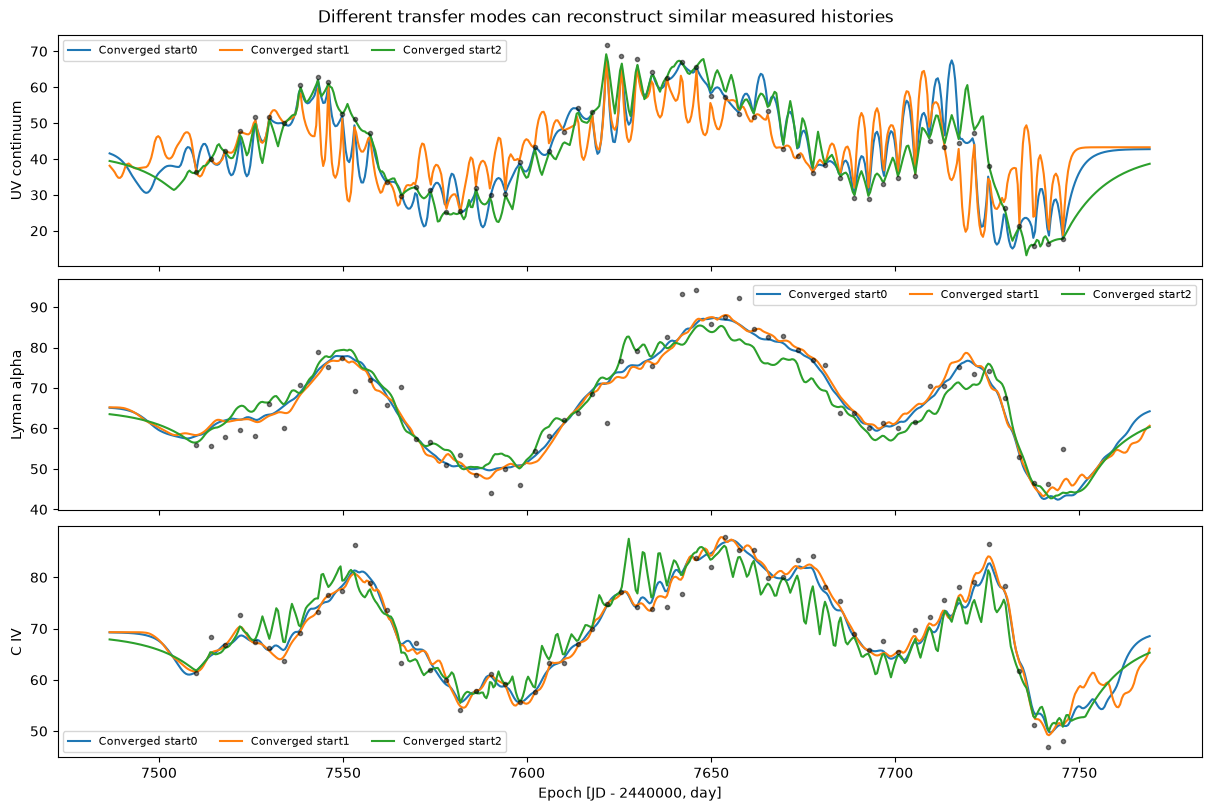

In [5]:
vis.transfer_modes(info); plt.show()
vis.mode_profiles(obs,info); plt.show()

### Conditional lag surface
We evaluate31x31lag combinations with the other6parameters fixed at the selected fit. This is a conditional objective slice, **not a reoptimized profile likelihood or calibrated confidence region**. It illustrates lag coupling without disguising missing parameter marginalization.

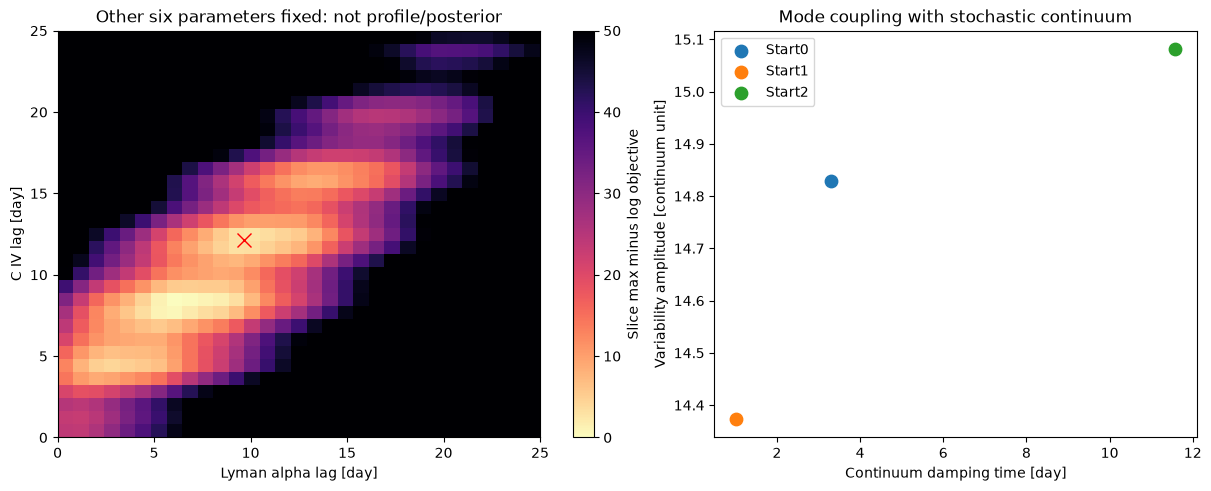

Finite likelihood-slice evaluations: 961


In [6]:
figure,lag_values=vis.lag_slice(obs,info); plt.show()
print("Finite likelihood-slice evaluations:",np.isfinite(lag_values).sum())

## Conclusion
All180real flux measurements are used to infer3latent histories and two broad-line transfer responses. Exact-observation original-code parity and independent covariance-integral checks support implementation correctness. They do not prove the inferred transfers are physically unique. Different modes, width-boundary behavior, finite cadence, model-dependent extrapolation and conditional-only uncertainty remain visible. There is no pristine dense GT, no measured black-hole mass, and no claim of reproducing the paper's full MCMC intervals. Source details, equation mapping, hashes and all execution evidence are in test/validation.md.